# Feature Scaling


Some Machine Learning models care a lot about the scale of the input features. If one variable is measured in fractions while another is measured in the hundreds or thousands, a distance-based model can treat the large-scale feature as much more important even when that is not what we want.

In this notebook, we use the wine dataset to compare a K-nearest neighbors classifier before and after feature scaling.


The core idea is simple:

```mermaid
flowchart LR
    A[Raw features on<br>different scales] --> B[KNN computes<br>distances]
    B --> C[Large-scale<br>features dominate]
    A --> D[StandardScaler]
    D --> E[Features on a<br>comparable scale]
    E --> F[More balanced<br>distance calculations]
```


## Load the Dataset


We use the wine dataset built into scikit-learn. It is a multi-class classification problem with only numerical features, which makes it a good example for scaling.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame.copy()
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Before training, it helps to inspect the feature scales. KNN uses distances between points, so a feature with values in the hundreds can easily dominate a feature with values near zero.


In [3]:
scale_overview = df.drop(columns="target").agg(["mean", "std", "min", "max"]).T
scale_overview

,mean,std,min,max
alcohol,13.000618,0.811827,11.03,14.83
malic_acid,2.336348,1.117146,0.74,5.80
ash,2.366517,0.274344,1.36,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,30.00
magnesium,99.741573,14.282484,70.00,162.00
total_phenols,2.295112,0.625851,0.98,3.88
flavanoids,2.029270,0.998859,0.34,5.08
nonflavanoid_phenols,0.361854,0.124453,0.13,0.66
proanthocyanins,1.590899,0.572359,0.41,3.58
color_intensity,5.058090,2.318286,1.28,13.00


Notice how different the ranges are. For example, features such as `proline` have much larger values than features such as `nonflavanoid_phenols`. Without scaling, that difference heavily influences distance-based models.


## Train a Baseline KNN Model


We first train a KNN classifier on the raw features. Because the dataset has multiple classes, we use `stratify=y` so the train and test split keep a similar class distribution.


In [4]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=1,
    stratify=y,
)

knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)

y_pred_raw = knn_raw.predict(X_test)
raw_accuracy = accuracy_score(y_test, y_pred_raw)
print(f"Accuracy without scaling: {raw_accuracy:.3f}")

Accuracy without scaling: 0.644


That baseline gives us a reference point. Next, we standardize the features so each column has roughly mean `0` and standard deviation `1` on the training data.


## Apply Standardization


`StandardScaler` learns the mean and standard deviation from the training data only. We then use the same transformation on the test set. This is important because fitting the scaler on all data would leak information from the test set into the training process.


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
scaled_train_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
scaled_train_df.agg(["mean", "std"]).T.head(10)

,mean,std
alcohol,1.549304e-15,1.003781
malic_acid,-1.335607e-16,1.003781
ash,1.602728e-16,1.003781
alcalinity_of_ash,-4.474282e-16,1.003781
magnesium,4.006820e-16,1.003781
total_phenols,-1.260479e-16,1.003781
flavanoids,-1.402387e-16,1.003781
nonflavanoid_phenols,-2.328964e-16,1.003781
proanthocyanins,-4.006820e-17,1.003781
color_intensity,1.711246e-17,1.003781


The table is helpful, but a visual comparison makes the scale problem even more obvious. The boxplots below compare a few features before and after scaling.


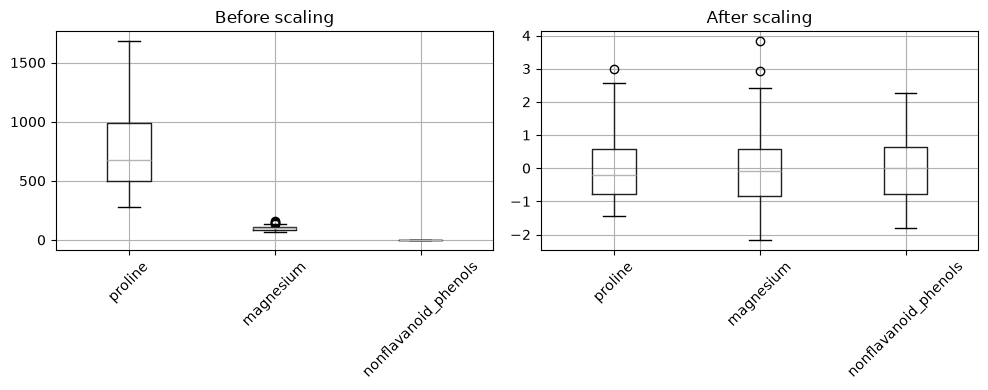

In [7]:
feature_subset = ["proline", "magnesium", "nonflavanoid_phenols"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df[feature_subset].boxplot(ax=axes[0])
axes[0].set_title("Before scaling")
axes[0].tick_params(axis="x", rotation=45)

scaled_train_df[feature_subset].boxplot(ax=axes[1])
axes[1].set_title("After scaling")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

The scaled training features are now centered near `0` and have similar spread. That gives distance-based algorithms a fairer view of all features.


## Train the Model on Scaled Features


In [8]:
knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = knn_scaled.predict(X_test_scaled)
scaled_accuracy = accuracy_score(y_test, y_pred_scaled)
print(f"Accuracy with scaling: {scaled_accuracy:.3f}")

Accuracy with scaling: 0.933


In practice, preprocessing and model training are often combined in a `Pipeline`. That keeps the workflow cleaner and makes it easier to reuse the same steps during cross-validation or deployment.

In [9]:
knn_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5)),
    ]
)

knn_pipeline.fit(X_train, y_train)
pipeline_accuracy = accuracy_score(y_test, knn_pipeline.predict(X_test))
print(f"Accuracy with a pipeline: {pipeline_accuracy:.3f}")

Accuracy with a pipeline: 0.933


## Compare the Results


In [10]:
pd.DataFrame(
    {
        "model": [
            "KNN without scaling",
            "KNN with StandardScaler",
            "KNN pipeline",
        ],
        "accuracy": [raw_accuracy, scaled_accuracy, pipeline_accuracy],
    }
)

,model,accuracy
0,KNN without scaling,0.644444
1,KNN with StandardScaler,0.933333
2,KNN pipeline,0.933333


The improvement happens because KNN depends directly on distances. When features are brought onto a comparable scale, no single high-magnitude column dominates the neighborhood calculation.

Feature scaling is especially important for models such as KNN, support vector machines, and logistic regression. Tree-based models such as decision trees and random forests are usually much less sensitive to scaling.
